In [22]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

### 1.	Load and explore the Iris dataset. Display its structure, features, and missing values. 


In [23]:
column_names = [
    'sepal_length',
    'sepal_width',
    'petal_length',
    'petal_width',
    'class',
]
df = pd.read_csv('iris.data', header=None, names=column_names)

print(df.head(), '\n')

df.info()
print('\n')

print(df.describe(), '\n')

print(df.isnull().sum())

   sepal_length  sepal_width  petal_length  petal_width        class
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   class         150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean 

### 2. Standardize the numerical attributes before applying K-means clustering. 

In [25]:
X = df.drop(columns=['class'])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

df_scaled = pd.DataFrame(X_scaled, columns=X.columns)

print(df_scaled.head(), '\n')
print(df_scaled.describe().round(2))

   sepal_length  sepal_width  petal_length  petal_width
0     -0.900681     1.032057     -1.341272    -1.312977
1     -1.143017    -0.124958     -1.341272    -1.312977
2     -1.385353     0.337848     -1.398138    -1.312977
3     -1.506521     0.106445     -1.284407    -1.312977
4     -1.021849     1.263460     -1.341272    -1.312977 

       sepal_length  sepal_width  petal_length  petal_width
count        150.00       150.00        150.00       150.00
mean          -0.00        -0.00          0.00         0.00
std            1.00         1.00          1.00         1.00
min           -1.87        -2.44         -1.57        -1.44
25%           -0.90        -0.59         -1.23        -1.18
50%           -0.05        -0.12          0.34         0.13
75%            0.67         0.57          0.76         0.79
max            2.49         3.11          1.79         1.71


### 3.	 Apply K-means with K=3 and report the SSE and number of iterations. 

In [26]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_scaled)

sse = kmeans.inertia_
n_iterations = kmeans.n_iter_

print(f'SSE: {sse:.4f}')
print(f'Number of Iterations to Converge: {n_iterations}')

SSE: 140.9658
Number of Iterations to Converge: 5


### 4. Run K-means for different values of K and tabulate SSE and number of iterations. 

In [27]:
results = []
for k in range(1, 10):
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X_scaled)
  results.append(
      {'K': k, 'SSE': round(kmeans.inertia_, 4), 'Iterations': kmeans.n_iter_}
  )

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

C:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


 K      SSE  Iterations
 1 600.0000           2
 2 223.7320           4
 3 140.9658           5
 4 114.3895           5
 5  91.0024           6
 6  80.2497           8
 7  71.8095          19
 8  62.6410          10
 9  54.2575           9


### 5.	Plot SSE against K and determine an appropriate number of clusters using the Elbow Method. 

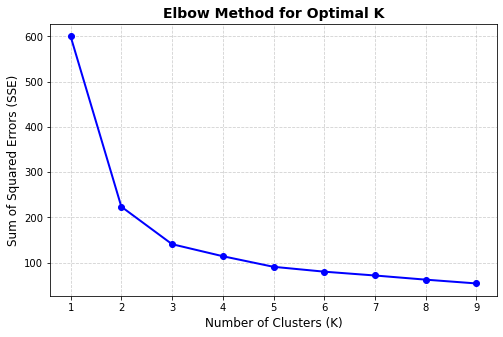

In [28]:
plt.figure(figsize=(8, 5))
plt.plot(
    results_df['K'],
    results_df['SSE'],
    marker='o',
    linestyle='-',
    color='b',
    linewidth=2,
    markersize=6,
)

plt.title('Elbow Method for Optimal K', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('Sum of Squared Errors (SSE)', fontsize=12)
plt.xticks(results_df['K'])
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 6.	Run K-means multiple times for each K and report average SSE and average iterations. 

In [29]:
avg_results = []
n_runs = 10

for k in range(1, 10):
  total_sse = 0
  total_iter = 0

  for run in range(n_runs):
    kmeans = KMeans(n_clusters=k, random_state=run, n_init=10)
    kmeans.fit(X_scaled)
    total_sse += kmeans.inertia_
    total_iter += kmeans.n_iter_

  avg_results.append({
      'K': k,
      'Avg SSE': round(total_sse / n_runs, 4),
      'Avg Iterations': round(total_iter / n_runs, 2),
  })

avg_results_df = pd.DataFrame(avg_results)
print(avg_results_df.to_string(index=False))

C:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\Anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Window

 K  Avg SSE  Avg Iterations
 1 600.0000             2.0
 2 223.7320             3.3
 3 140.9658             4.7
 4 114.5821             5.6
 5  91.1144             9.1
 6  80.9627             6.8
 7  71.6478             5.9
 8  63.3434             6.8
 9  54.5577             6.8


### 7.	Visualize the clusters obtained for K=3 using petal length and petal width. 

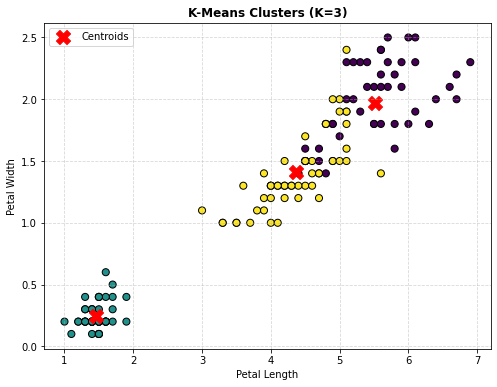

In [31]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

centers_original = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))
plt.scatter(
    df['petal_length'],
    df['petal_width'],
    c=df['Cluster'],
    cmap='viridis',
    s=50,
    edgecolor='k',
)
plt.scatter(
    centers_original[:, 2],
    centers_original[:, 3],
    c='red',
    marker='X',
    s=200,
    label='Centroids',
)

plt.title('K-Means Clusters (K=3)', fontsize=12, fontweight='bold')
plt.xlabel('Petal Length')
plt.ylabel('Petal Width')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()